<a href="https://colab.research.google.com/github/veekshavkamath-blip/CRIME-LOGISTIC-REGRESSION/blob/main/CRIME-LOGISTIC%20REGRESSION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [160]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [161]:
train = pd.read_csv('crime_train.csv')
test = pd.read_csv('crime_test.csv')

In [162]:
test.head()

,Unnamed: 0,Num,case_filed,city,area,crime_description,age,sex,weapon,domain,police_department,closed
0,32079,32080,08-29-2023 15:00,Pune,589,VEHICLE - STOLEN,57.0,M,Explosives,Violent Crime,13.0,Yes
1,39119,39120,06-17-2024 23:00,Ahmedabad,596,HOMICIDE,49.0,F,Other,Other Crime,10.0,Yes
2,34553,34554,12-10-2023 17:00,Mumbai,337,PUBLIC INTOXICATION,41.0,M,Firearm,Other Crime,12.0,Yes
3,29684,29685,05-21-2023 20:00,Hyderabad,252,TRAFFIC VIOLATION,15.0,F,Other,Traffic Fatality,11.0,Yes
4,20673,20674,05-11-2022 09:00,Hyderabad,340,VEHICLE - STOLEN,42.0,F,Other,Violent Crime,18.0,Yes


In [163]:
print(train.shape, test.shape)
print(train.isnull().sum())

(22489, 12) (9639, 12)
Unnamed: 0              0
Num                     0
case_filed              0
city                    0
area                    0
crime_description       0
age                     0
sex                     0
weapon               3272
domain                  0
police_department       0
closed                  0
dtype: int64


In [164]:
train['weapon'] = train['weapon'].fillna('Unknown')
test['weapon'] = test['weapon'].fillna('Unknown')


In [165]:
train = train.drop(columns=['Unnamed: 0', 'Num'], errors='ignore')
test = test.drop(columns=['Unnamed: 0', 'Num'], errors='ignore')

In [166]:
(train[['city','area','crime_description','police_department']].nunique())

,0
city,29
area,500
crime_description,21
police_department,57


In [167]:
top_areas = train['area'].value_counts().head(20).index.tolist()

train['area'] = train['area'].apply(lambda a: a if a in top_areas else 'Other')
test['area'] = test['area'].apply(lambda a: a if a in top_areas else 'Other')

In [168]:
for c in train.select_dtypes(exclude='number').columns:
    top = train[c].value_counts().head(20).index
    train[c] = train[c].where(train[c].isin(top), 'Other')
    test[c] = test[c].where(test[c].isin(top), 'Other')

In [169]:
y_train = train['closed'].map({'Yes': 1, 'No': 0}).values.astype(float)
y_test = test['closed'].map({'Yes': 1, 'No': 0}).values.astype(float)


In [170]:
train = train.drop(columns='closed')
test = test.drop(columns='closed')
train = pd.get_dummies(train, dtype=float)
test = pd.get_dummies(test, dtype=float)
test = test.reindex(columns=train.columns, fill_value=0)
x_train = train.values
x_test = test.values
print(x_train.shape, x_test.shape)

(22489, 99) (9639, 99)


In [171]:
Mean = x_train.mean(axis=0)
sigma = x_train.std(axis=0)
sigma[sigma == 0] = 1
#z-score normalization
x_train = (x_train - Mean) / sigma
x_test = (x_test - Mean)/ sigma

In [172]:
x_train = np.c_[np.ones(len(x_train)), x_train]
x_test = np.c_[np.ones(len(x_test)), x_test]

In [173]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def gradient_descent(X, y, alpha=0.05, lam=1, iters=500):
    m, n = X.shape
    w = np.zeros(n)
    costs = []
    eps = 1e-9
    for _ in range(iters):
        p = sigmoid(X @ w)
        err = p - y
        reg = lam * w
        reg[0] = 0
        w -= alpha * (X.T @ err + reg) / m

        p = sigmoid(X @ w)
        cost = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
        cost += lam * np.sum(w[1:] ** 2) / (2 * m)
        costs.append(cost)
    return w, costs


<Axes: title={'center': 'Effect of learning rate on training loss'}, xlabel='Epoch', ylabel='Loss'>

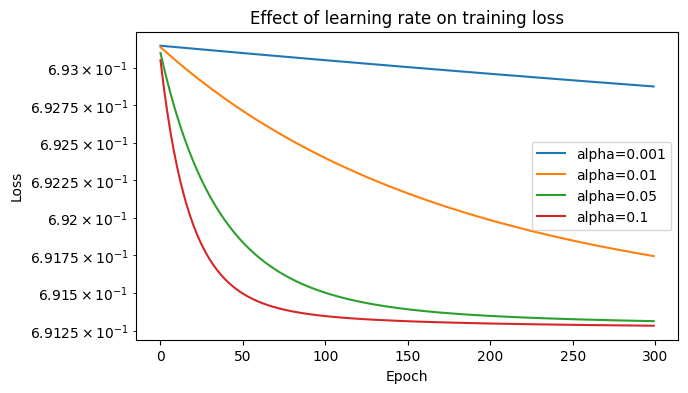

In [174]:
lr_hist = {}
for alpha in [0.001, 0.01, 0.05, 0.1]:
    _, h = gradient_descent(x_train, y_train, alpha=alpha, iters=300,lam=0)
    lr_hist[f'alpha={alpha}'] = h
pd.DataFrame(lr_hist).plot(figsize=(7,4), title='Effect of learning rate on training loss', logy=True,
                           xlabel='Epoch', ylabel='Loss')

<Axes: title={'center': 'Effect of lam on training loss'}, xlabel='Epoch', ylabel='Loss'>

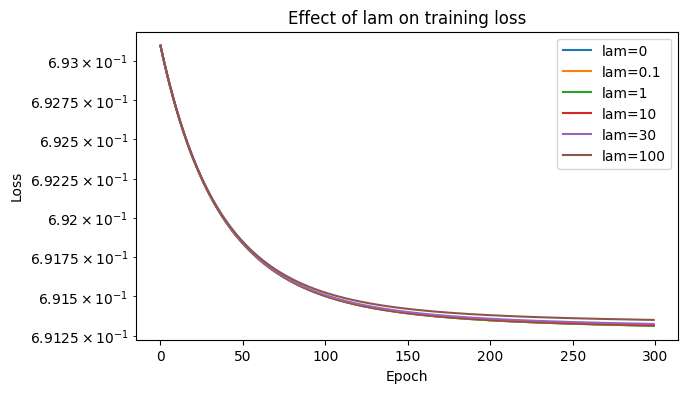

In [175]:
lam_hist = {}
for lam in [0, 0.1, 1, 10, 30, 100]:
    _, h = gradient_descent(x_train, y_train, alpha=0.05, iters=300, lam=lam)
    lam_hist[f'lam={lam}'] = h

pd.DataFrame(lam_hist).plot(figsize=(7, 4), title='Effect of lam on training loss', logy=True,
                            xlabel='Epoch', ylabel='Loss')

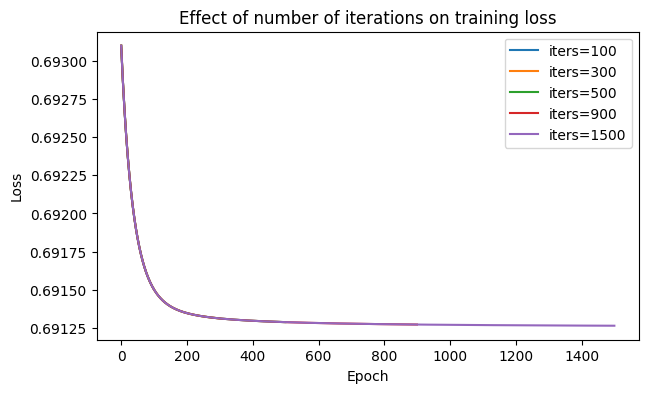

In [176]:
plt.figure(figsize=(7, 4))
for iters in [100, 300, 500, 900, 1500]:
    _, h = gradient_descent(x_train, y_train, alpha=0.05, iters=iters, lam=1)
    plt.plot(h, label=f'iters={iters}')

plt.title('Effect of number of iterations on training loss')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.legend()
plt.show()

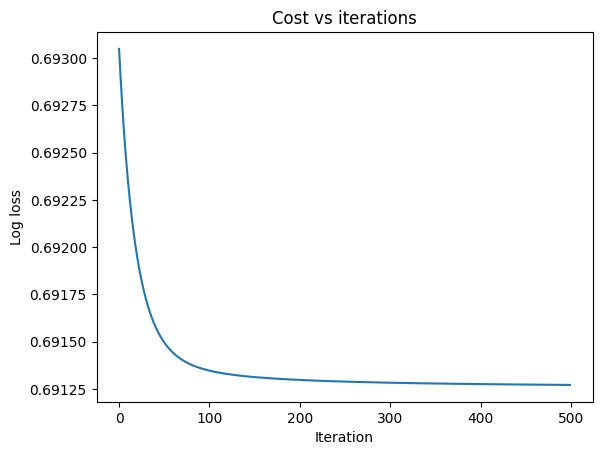

In [177]:
w, costs = gradient_descent(x_train, y_train, alpha=0.1, lam=1, iters=500)

plt.plot(costs)
plt.xlabel('Iteration'); plt.ylabel('Log loss'); plt.title('Cost vs iterations')
plt.show()

In [178]:
def predict(X, w, threshold=0.5):
    return (sigmoid(X @ w) >= threshold).astype(int)

def evaluate(X, y, w, name):
    pred = predict(X, w)
    tp = np.sum((pred == 1) & (y == 1))
    fp = np.sum((pred == 1) & (y == 0))
    fn = np.sum((pred == 0) & (y == 1))
    tn = np.sum((pred == 0) & (y == 0))
    acc = (tp + tn) / len(y)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    print(f"{name}: Accuracy {acc:.4f}\n | Precision {prec:.4f}\n| Recall {rec:.4f}")
    print(f"   TP {tp}\n  FP {fp}\n  FN {fn}\n  TN {tn}\n")

evaluate(x_train, y_train, w, "Train")
evaluate(x_test, y_test, w, "Test")
print("Majority-class baseline:", max(y_test.mean(), 1 - y_test.mean()))

Train: Accuracy 0.5180
 | Precision 0.5181
| Recall 0.5279
   TP 5941
  FP 5527
  FN 5312
  TN 5709

Test: Accuracy 0.4974
 | Precision 0.4977
| Recall 0.5022
   TP 2422
  FP 2444
  FN 2401
  TN 2372

Majority-class baseline: 0.5003631082062454
